In [1]:
import pandas as pd
import numpy as np

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd().parent
PROCESSED_DIR = PROJECT_DIR / "dataset" / "processed"

csv_files = sorted(PROCESSED_DIR.glob("*.csv"))

print("Total CSV files:", len(csv_files))
print([file.name for file in csv_files])

Total CSV files: 8
['Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv', 'Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv', 'Friday-WorkingHours-Morning.pcap_ISCX.csv', 'Monday-WorkingHours.pcap_ISCX.csv', 'Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv', 'Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv', 'Tuesday-WorkingHours.pcap_ISCX.csv', 'Wednesday-workingHours.pcap_ISCX.csv']


In [3]:
# Load a 5% sample from all 8 cleaned files

data = []

for file in csv_files:
    for chunk in pd.read_csv(file, chunksize=100000):
        sample = chunk.sample(frac=0.05, random_state=42)
        data.append(sample)

df = pd.concat(data, ignore_index=True)

# Convert labels into binary classes
df["Label"] = (df["Label"].str.strip().str.upper() != "BENIGN").astype(int)

print("Dataset shape:", df.shape)
print("\nClass distribution:")
print(df["Label"].value_counts())

Dataset shape: (131834, 79)

Class distribution:
Label
0    109317
1     22517
Name: count, dtype: int64


In [4]:
X = df.drop(columns=["Label"])
y = df["Label"]

# Keep numeric features only
X = X.select_dtypes(include=["number"])

# Replace infinite values and missing values
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

print("Input features:", X.shape)
print("Target:", y.shape)

Input features: (131834, 78)
Target: (131834,)


In [5]:
#Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (105467, 78)
Testing data: (26367, 78)


In [6]:
##Train the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


Accuracy: 0.9979519854363409

Classification Report:
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00     21864
      ATTACK       0.99      0.99      0.99      4503

    accuracy                           1.00     26367
   macro avg       1.00      1.00      1.00     26367
weighted avg       1.00      1.00      1.00     26367



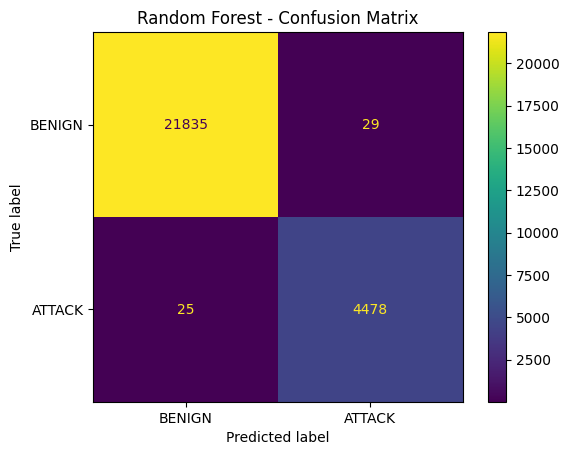

In [7]:
#Evaluate the Random Forest model

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict test data
y_pred = rf_model.predict(X_test)

# Model accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))

# Detailed performance report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["BENIGN", "ATTACK"]
))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["BENIGN", "ATTACK"]
).plot()

plt.title("Random Forest - Confusion Matrix")
plt.show()

In [8]:
train_hash = pd.util.hash_pandas_object(X_train, index=False)
test_hash = pd.util.hash_pandas_object(X_test, index=False)

print("Duplicate rows:", test_hash.isin(train_hash).sum())

Duplicate rows: 166


In [9]:
# Separate files by day
train_files = [f for f in csv_files if "Friday" not in f.name]
test_files = [f for f in csv_files if "Friday" in f.name]

print("Training files:", len(train_files))
print("Testing files:", len(test_files))

Training files: 5
Testing files: 3


In [10]:
def load_sample(files):
    frames = []

    for file in files:
        for chunk in pd.read_csv(file, chunksize=100000):
            frames.append(chunk.sample(frac=0.05, random_state=42))

    return pd.concat(frames, ignore_index=True)


train_df = load_sample(train_files)
test_df = load_sample(test_files)

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

Training shape: (99424, 79)
Testing shape: (32410, 79)


In [11]:
# Convert labels: BENIGN = 0, ATTACK = 1
train_df["Label"] = (train_df["Label"].str.strip().str.upper() != "BENIGN").astype(int)
test_df["Label"] = (test_df["Label"].str.strip().str.upper() != "BENIGN").astype(int)

# Separate features and target
X_train_day = train_df.drop(columns=["Label"]).select_dtypes(include="number")
X_test_day = test_df.drop(columns=["Label"]).select_dtypes(include="number")

y_train_day = train_df["Label"]
y_test_day = test_df["Label"]

# Keep matching feature columns
X_test_day = X_test_day.reindex(columns=X_train_day.columns)

# Handle missing and infinite values using training medians
X_train_day = X_train_day.replace([np.inf, -np.inf], np.nan)
X_test_day = X_test_day.replace([np.inf, -np.inf], np.nan)

medians = X_train_day.median()

X_train_day = X_train_day.fillna(medians)
X_test_day = X_test_day.fillna(medians)

print("Training features:", X_train_day.shape)
print("Testing features:", X_test_day.shape)

Training features: (99424, 78)
Testing features: (32410, 78)


In [12]:
rf_day_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

rf_day_model.fit(X_train_day, y_train_day)

day_predictions = rf_day_model.predict(X_test_day)

print("Day-Wise Accuracy:", accuracy_score(y_test_day, day_predictions))
print(classification_report(
    y_test_day,
    day_predictions,
    target_names=["BENIGN", "ATTACK"],
    zero_division=0
))

Day-Wise Accuracy: 0.7486269669854984
              precision    recall  f1-score   support

      BENIGN       0.71      1.00      0.83     20238
      ATTACK       1.00      0.33      0.50     12172

    accuracy                           0.75     32410
   macro avg       0.86      0.67      0.66     32410
weighted avg       0.82      0.75      0.71     32410



In [13]:
from xgboost import XGBClassifier

In [14]:
##Train the XGBoost model

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

print("XGBoost training completed!")

XGBoost training completed!


In [ ]:
##Evaluate on random test data

xgb_pred = xgb_model.predict(X_test)

print("XGBoost Random-Split Accuracy:",
      accuracy_score(y_test, xgb_pred))

print(classification_report(
    y_test, xgb_pred,
    target_names=["BENIGN", "ATTACK"]

))

XGBoost Random-Split Accuracy: 0.9990139189137938
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00     21864
      ATTACK       1.00      1.00      1.00      4503

    accuracy                           1.00     26367
   macro avg       1.00      1.00      1.00     26367
weighted avg       1.00      1.00      1.00     26367



In [16]:
##Evaluate XGBoost on Friday data

xgb_day_pred = xgb_model.predict(X_test_day)

print("XGBoost Day-Wise Accuracy:",
      accuracy_score(y_test_day, xgb_day_pred))

print(classification_report(
    y_test_day,
    xgb_day_pred,
    target_names=["BENIGN", "ATTACK"]
))

XGBoost Day-Wise Accuracy: 0.9992903424868868
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00     20238
      ATTACK       1.00      1.00      1.00     12172

    accuracy                           1.00     32410
   macro avg       1.00      1.00      1.00     32410
weighted avg       1.00      1.00      1.00     32410



In [17]:
# Train XGBoost using only Monday-Thursday data

xgb_day_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_day_model.fit(X_train_day, y_train_day)

print("Day-wise XGBoost training completed!")

Day-wise XGBoost training completed!


In [ ]:
##Evaluate it on Friday

xgb_day_pred = xgb_day_model.predict(X_test_day)

print("Day-Wise XGBoost Accuracy:",
      accuracy_score(y_test_day, xgb_day_pred))

print(classification_report(
    y_test_day,
    xgb_day_pred,
    target_names=["BENIGN", "ATTACK"]
))

Day-Wise XGBoost Accuracy: 0.711385374884295
              precision    recall  f1-score   support

      BENIGN       0.68      1.00      0.81     20238
      ATTACK       1.00      0.23      0.38     12172

    accuracy                           0.71     32410
   macro avg       0.84      0.62      0.59     32410
weighted avg       0.80      0.71      0.65     32410



In [20]:
def get_attack_types(files):
    labels = set()

    for file in files:
        for chunk in pd.read_csv(file, usecols=["Label"], chunksize=100000):
            labels.update(chunk["Label"].dropna().astype(str).str.strip().unique())

    return sorted(labels)


train_labels = get_attack_types(train_files)
test_labels = get_attack_types(test_files)

print("Training attack categories:")
print([x for x in train_labels if x.upper() != "BENIGN"])

print("\nFriday attack categories:")
print([x for x in test_labels if x.upper() != "BENIGN"])

Training attack categories:
['DoS GoldenEye', 'DoS Hulk', 'DoS Slowhttptest', 'DoS slowloris', 'FTP-Patator', 'Heartbleed', 'Infiltration', 'SSH-Patator', 'Web Attack � Brute Force', 'Web Attack � Sql Injection', 'Web Attack � XSS']

Friday attack categories:
['Bot', 'DDoS', 'PortScan']


In [21]:
from sklearn.metrics import accuracy_score

# Random Forest
rf_train_pred = rf_model.predict(X_train)
rf_test_pred = rf_model.predict(X_test)

# XGBoost
xgb_train_pred = xgb_model.predict(X_train)
xgb_test_pred = xgb_model.predict(X_test)

print("RANDOM FOREST")
print("Training Accuracy:", accuracy_score(y_train, rf_train_pred))
print("Testing Accuracy:", accuracy_score(y_test, rf_test_pred))

print("\nXGBOOST")
print("Training Accuracy:", accuracy_score(y_train, xgb_train_pred))
print("Testing Accuracy:", accuracy_score(y_test, xgb_test_pred))

RANDOM FOREST
Training Accuracy: 0.9996586610029677
Testing Accuracy: 0.9979519854363409

XGBOOST
Training Accuracy: 0.9993836934775807
Testing Accuracy: 0.9990139189137938


Final Model – Data Leakage Prevention

In [22]:
# Remove exact duplicate records
df_final = df.drop_duplicates().copy()

print("Original records:", len(df))
print("Records after removing duplicates:", len(df_final))
print("Duplicates removed:", len(df) - len(df_final))

Original records: 131834
Records after removing duplicates: 131335
Duplicates removed: 499


In [24]:
X_final = df_final.drop(columns=["Label"]).select_dtypes(include="number")

# Label is already binary: 0 = BENIGN, 1 = ATTACK
y_final = df_final["Label"].astype(int)

X_final = X_final.replace([np.inf, -np.inf], np.nan)

print("Features:", X_final.shape)

print("\nTarget distribution:")
print(y_final.value_counts())

Features: (131335, 78)

Target distribution:
Label
0    108891
1     22444
Name: count, dtype: int64


In [25]:
X_train_final, X_test_final, y_train_final, y_test_final = train_test_split(
    X_final,
    y_final,
    test_size=0.20,
    random_state=42,
    stratify=y_final
)

# Calculate medians using training data only
medians = X_train_final.median()

# Handle missing values
X_train_final = X_train_final.fillna(medians)
X_test_final = X_test_final.fillna(medians)

print("Training data:", X_train_final.shape)
print("Testing data:", X_test_final.shape)

print("\nTraining target distribution:")
print(y_train_final.value_counts())

print("\nTesting target distribution:")
print(y_test_final.value_counts())

Training data: (105068, 78)
Testing data: (26267, 78)

Training target distribution:
Label
0    87113
1    17955
Name: count, dtype: int64

Testing target distribution:
Label
0    21778
1     4489
Name: count, dtype: int64


In [26]:
print("Missing values in training data:", X_train_final.isnull().sum().sum())
print("Missing values in testing data:", X_test_final.isnull().sum().sum())

Missing values in training data: 0
Missing values in testing data: 0


In [27]:
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

feature_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

feature_model.fit(X_train_final, y_train_final)

feature_importance = pd.DataFrame({
    "Feature": X_train_final.columns,
    "Importance": feature_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance", ascending=False
)

print("Top 20 Important Features:")
print(feature_importance.head(20))

Top 20 Important Features:
                        Feature  Importance
39            Max Packet Length    0.082070
41            Packet Length Std    0.064271
52          Average Packet Size    0.060841
42       Packet Length Variance    0.057777
54         Avg Bwd Segment Size    0.055323
10        Bwd Packet Length Max    0.039691
0              Destination Port    0.037573
13        Bwd Packet Length Std    0.037494
8        Fwd Packet Length Mean    0.033726
67      Init_Win_bytes_backward    0.028470
5   Total Length of Bwd Packets    0.026717
66       Init_Win_bytes_forward    0.026451
6         Fwd Packet Length Max    0.026033
53         Avg Fwd Segment Size    0.025679
40           Packet Length Mean    0.025604
12       Bwd Packet Length Mean    0.024159
4   Total Length of Fwd Packets    0.020098
55          Fwd Header Length.1    0.019070
63            Subflow Fwd Bytes    0.018260
17                 Flow IAT Std    0.015797


In [28]:
# Select the top 20 features
top_20_features = feature_importance.head(20)["Feature"].tolist()

X_train_20 = X_train_final[top_20_features]
X_test_20 = X_test_final[top_20_features]

print("Original number of features:", X_train_final.shape[1])
print("Selected number of features:", X_train_20.shape[1])

Original number of features: 78
Selected number of features: 20


In [29]:
##Train the Random Forest model using 20 features

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

rf_20_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

rf_20_model.fit(X_train_20, y_train_final)

y_pred_rf_20 = rf_20_model.predict(X_test_20)

print("Random Forest – Top 20 Features")
print("Accuracy:", accuracy_score(y_test_final, y_pred_rf_20))

print("\nClassification Report:")
print(classification_report(
    y_test_final,
    y_pred_rf_20,
    target_names=["BENIGN", "ATTACK"]
))

Random Forest – Top 20 Features
Accuracy: 0.9972208474511745

Classification Report:
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00     21778
      ATTACK       0.99      1.00      0.99      4489

    accuracy                           1.00     26267
   macro avg       0.99      1.00      1.00     26267
weighted avg       1.00      1.00      1.00     26267



In [30]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

comparison = pd.DataFrame({
    "Model": ["Random Forest - 78 Features", "Random Forest - 20 Features"],
    "Accuracy": [
        accuracy_score(y_test_final, rf_model.predict(X_test_final)),
        accuracy_score(y_test_final, y_pred_rf_20)
    ],
    "Attack Precision": [
        precision_score(y_test_final, rf_model.predict(X_test_final)),
        precision_score(y_test_final, y_pred_rf_20)
    ],
    "Attack Recall": [
        recall_score(y_test_final, rf_model.predict(X_test_final)),
        recall_score(y_test_final, y_pred_rf_20)
    ],
    "Attack F1-Score": [
        f1_score(y_test_final, rf_model.predict(X_test_final)),
        f1_score(y_test_final, y_pred_rf_20)
    ]
})

print(comparison.round(4))

                         Model  Accuracy  Attack Precision  Attack Recall  \
0  Random Forest - 78 Features    0.9992            0.9967         0.9987   
1  Random Forest - 20 Features    0.9972            0.9878         0.9960   

   Attack F1-Score  
0           0.9977  
1           0.9919  


In [31]:
from sklearn.metrics import accuracy_score, recall_score, f1_score

y_train_pred = rf_model.predict(X_train_final)
y_test_pred = rf_model.predict(X_test_final)

print("TRAINING PERFORMANCE")
print("Accuracy:", accuracy_score(y_train_final, y_train_pred))
print("Attack Recall:", recall_score(y_train_final, y_train_pred))
print("Attack F1:", f1_score(y_train_final, y_train_pred))

print("\nTESTING PERFORMANCE")
print("Accuracy:", accuracy_score(y_test_final, y_test_pred))
print("Attack Recall:", recall_score(y_test_final, y_test_pred))
print("Attack F1:", f1_score(y_test_final, y_test_pred))

TRAINING PERFORMANCE
Accuracy: 0.9993432824456543
Attack Recall: 0.9989417989417989
Attack F1: 0.9980801869730948

TESTING PERFORMANCE
Accuracy: 0.9992005177599269
Attack Recall: 0.9986633994208064
Attack F1: 0.9976632914209413


In [ ]:
# Check data quality in each CSV file

for file in csv_files:
    df = pd.read_csv(file, nrows=10000)

    df.columns = df.columns.str.strip()

    print("\nFile:", file.name)
    print("Rows checked:", len(df))
    print("Missing values:", df.isnull().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())
    print("Infinite values:", np.isinf(
        df.select_dtypes(include=np.number)
    ).sum().sum())


File: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Rows checked: 10000
Missing values: 1
Duplicate rows: 73
Infinite values: 13

File: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Rows checked: 10000
Missing values: 0
Duplicate rows: 137
Infinite values: 4

File: Friday-WorkingHours-Morning.pcap_ISCX.csv
Rows checked: 10000
Missing values: 0
Duplicate rows: 147
Infinite values: 12

File: Monday-WorkingHours.pcap_ISCX.csv
Rows checked: 10000
Missing values: 1
Duplicate rows: 127
Infinite values: 35

File: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Rows checked: 10000
Missing values: 0
Duplicate rows: 101
Infinite values: 8

File: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Rows checked: 10000
Missing values: 2
Duplicate rows: 134
Infinite values: 26

File: Tuesday-WorkingHours.pcap_ISCX.csv
Rows checked: 10000
Missing values: 10
Duplicate rows: 189
Infinite values: 18

File: Wednesday-workingHours.pcap_ISCX.csv
Rows checked: 10000
Missing values:

Unseen-Day Validation

In [32]:
# Load Monday–Thursday and Friday samples separately
train_df_day = load_sample(train_files)
test_df_day = load_sample(test_files)

# Create binary labels
y_train_day = (
    train_df_day["Label"].astype(str).str.strip().str.upper() != "BENIGN"
).astype(int)

y_test_day = (
    test_df_day["Label"].astype(str).str.strip().str.upper() != "BENIGN"
).astype(int)

# Select numeric features
X_train_day = train_df_day.drop(columns=["Label"]).select_dtypes(include="number")
X_test_day = test_df_day.drop(columns=["Label"]).select_dtypes(include="number")

# Align test features with training features
X_test_day = X_test_day.reindex(columns=X_train_day.columns)

# Replace infinite values
X_train_day = X_train_day.replace([np.inf, -np.inf], np.nan)
X_test_day = X_test_day.replace([np.inf, -np.inf], np.nan)

# Handle missing values using training medians
day_medians = X_train_day.median()
X_train_day = X_train_day.fillna(day_medians)
X_test_day = X_test_day.fillna(day_medians)

print("Training data:", X_train_day.shape)
print("Testing data:", X_test_day.shape)

print("\nTraining labels:")
print(y_train_day.value_counts())

print("\nTesting labels:")
print(y_test_day.value_counts())

Training data: (99424, 78)
Testing data: (32410, 78)

Training labels:
Label
0    89079
1    10345
Name: count, dtype: int64

Testing labels:
Label
0    20238
1    12172
Name: count, dtype: int64


In [33]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

rf_day_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

# Train using Monday–Thursday data
rf_day_model.fit(X_train_day, y_train_day)

# Predict Friday traffic
y_pred_rf_day = rf_day_model.predict(X_test_day)

print("Random Forest - Unseen-Day Validation")
print("Accuracy:", accuracy_score(y_test_day, y_pred_rf_day))

print("\nClassification Report:")
print(classification_report(
    y_test_day,
    y_pred_rf_day,
    target_names=["BENIGN", "ATTACK"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_day, y_pred_rf_day))

Random Forest - Unseen-Day Validation
Accuracy: 0.7486269669854984

Classification Report:
              precision    recall  f1-score   support

      BENIGN       0.71      1.00      0.83     20238
      ATTACK       1.00      0.33      0.50     12172

    accuracy                           0.75     32410
   macro avg       0.86      0.67      0.66     32410
weighted avg       0.82      0.75      0.71     32410


Confusion Matrix:
[[20230     8]
 [ 8139  4033]]


In [34]:
# Combine actual labels and model predictions
results = test_df_day.copy()

results["Actual"] = y_test_day.values
results["Predicted"] = y_pred_rf_day

# Display attack-wise detection performance
attack_analysis = results[results["Actual"] == 1].groupby("Label").apply(
    lambda group: pd.Series({
        "Total Attacks": len(group),
        "Detected": (group["Predicted"] == 1).sum(),
        "Missed": (group["Predicted"] == 0).sum(),
        "Recall (%)": (group["Predicted"] == 1).mean() * 100
    }),
    include_groups=False
)

print(attack_analysis.round(2))

          Total Attacks  Detected  Missed  Recall (%)
Label                                                
Bot                96.0       0.0    96.0        0.00
DDoS             6338.0    4020.0  2318.0       63.43
PortScan         5738.0      13.0  5725.0        0.23


In [35]:
# Compare selected network traffic features by attack category

selected_features = [
    "Destination Port",
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Packet Length Mean",
    "Packet Length Std",
    "Average Packet Size"
]

attack_comparison = test_df_day.groupby("Label")[
    selected_features
].mean()

print(attack_comparison.round(2))

          Destination Port  Flow Duration  Total Fwd Packets  \
Label                                                          
BENIGN            10428.00    12950862.03               7.27   
Bot               15185.68      295844.43               3.53   
DDoS                 80.00    16832896.58               4.47   
PortScan           8512.92       62912.44               1.02   

          Total Backward Packets  Packet Length Mean  Packet Length Std  \
Label                                                                     
BENIGN                      7.96              135.29             210.75   
Bot                         4.00               62.10             119.13   
DDoS                        3.26              736.40            1575.00   
PortScan                    1.01                3.96               5.13   

          Average Packet Size  
Label                          
BENIGN                 152.82  
Bot                     66.17  
DDoS                   822.10  
Port

In [ ]:
##Train XGBoost on unseen-day data

from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

xgb_day_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# Train on Monday–Thursday
xgb_day_model.fit(X_train_day, y_train_day)

# Test on Friday
y_pred_xgb_day = xgb_day_model.predict(X_test_day)

print("XGBoost - Unseen-Day Validation")
print("Accuracy:", accuracy_score(y_test_day, y_pred_xgb_day))

print("\nClassification Report:")
print(classification_report(
    y_test_day,
    y_pred_xgb_day,
    target_names=["BENIGN", "ATTACK"]
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_day, y_pred_xgb_day))

XGBoost - Unseen-Day Validation
Accuracy: 0.711385374884295

Classification Report:
              precision    recall  f1-score   support

      BENIGN       0.68      1.00      0.81     20238
      ATTACK       1.00      0.23      0.38     12172

    accuracy                           0.71     32410
   macro avg       0.84      0.62      0.59     32410
weighted avg       0.80      0.71      0.65     32410


Confusion Matrix:
[[20236     2]
 [ 9352  2820]]


In [37]:

for file in csv_files:
    print("\nFile:", file.name)

    labels = pd.read_csv(file, usecols=["Label"])["Label"]

    print(labels.value_counts().head(10))


File: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Label
DDoS      128021
BENIGN     95854
Name: count, dtype: int64

File: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Label
BENIGN      124040
PortScan    114652
Name: count, dtype: int64

File: Friday-WorkingHours-Morning.pcap_ISCX.csv
Label
BENIGN    183673
Bot         1956
Name: count, dtype: int64

File: Monday-WorkingHours.pcap_ISCX.csv
Label
BENIGN    512438
Name: count, dtype: int64

File: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Label
BENIGN          260462
Infiltration        36
Name: count, dtype: int64

File: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Label
BENIGN                        163394
Web Attack � Brute Force        1470
Web Attack � XSS                 652
Web Attack � Sql Injection        21
Name: count, dtype: int64

File: Tuesday-WorkingHours.pcap_ISCX.csv
Label
BENIGN         419782
FTP-Patator      5935
SSH-Patator      3545
Name: count, dtype: int64

File: Wednesday

In [38]:
label_summary = []

for file in csv_files:
    labels = pd.read_csv(file, usecols=["Label"])["Label"]

    counts = labels.value_counts()

    for label, count in counts.items():
        label_summary.append({
            "File": file.name,
            "Attack Category": label,
            "Records": count
        })

label_summary_df = pd.DataFrame(label_summary)

print(label_summary_df.to_string(index=False))

                                                       File            Attack Category  Records
           Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv                       DDoS   128021
           Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv                     BENIGN    95854
       Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv                     BENIGN   124040
       Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv                   PortScan   114652
                  Friday-WorkingHours-Morning.pcap_ISCX.csv                     BENIGN   183673
                  Friday-WorkingHours-Morning.pcap_ISCX.csv                        Bot     1956
                          Monday-WorkingHours.pcap_ISCX.csv                     BENIGN   512438
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv                     BENIGN   260462
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv               Infiltration       36
     Thursday-WorkingHours-Morning-WebAt

In [39]:
import joblib

MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

model_artifact = {
    "model": rf_model,
    "features": X_train_final.columns.tolist(),
    "medians": medians
}

model_path = MODEL_DIR / "cyberattack_rf_model.joblib"

joblib.dump(model_artifact, model_path)

print("Model saved successfully!")
print("Location:", model_path)

Model saved successfully!
Location: c:\Users\Swapnil\OneDrive\Desktop\ML project\models\cyberattack_rf_model.joblib
